In [87]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import evolve_feedback
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve

In [88]:
help(util.dynamics.evolve)

Help on function evolve in module util.dynamics:

evolve(D_init, A, no_time_steps, order_ST=True, pc=None, tau_c=None, T=None, beta=None, T_lim=None, pr=None, tau_r=None)
    Wrapper to evolve system up to and including t = no_time_steps,
    with an initial value of D_init at time t=0.

    Parameters (required)
    ---
    D_init : numpy.array
        The initial array of degraded probabilities at time step 0
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D_init), len(D_init)).
        No self loops, i.e. all diagonal elements should be 0.
    no_time_steps : int
        The number of time steps to simulate over,
        i.e. the number of times the update equation is successively applied.
        Must be >= 1

    Parameters (optional):
    order_ST : Bool
        The indexing order of the adjacent matrix.
        If True, then the adjacency matrix will be read with an index-order that gives A[source, target].
        Otherwise the 

In [101]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy()
beta = df_TEs['Beta (1/°C)'].to_numpy()
pr = 1/(1+df_TEs['Recovery (years)'].to_numpy())
tau_c = df_TEs['Collapse (years)'].to_numpy()

folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

In [98]:
df_TEs.head()

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN


# TIPMIP

In [19]:
def TIPMIP_temps(T_peak=2.5, T_conv=0, t_peak=200, t_end = 5000):
    # hard coded speed of ramp up and ramp down as +- 0.2C/decade
    # also hard coded each time step as 1 year
    if T_peak < T_conv:
        raise ValueError("T_peak is smaller than T_conv, this would be an undershoot not overshoot.")

    temp = np.concatenate((np.arange(0,T_peak+.01,step=0.02), # ramp up from 0 -> T_peak at a rate of +0.2C/dec
                           np.ones(t_peak)*T_peak, # remain at peak for t_peak years
                           np.arange(T_conv,T_peak,step=0.02)[::-1])) # ramp down from T_peak -> T_conv at a rate of -0.2C/dec
    if t_end <= len(temp):
        return temp[:t_end]                          
    else:
        return np.concatenate((temp, np.ones(t_end-len(temp))*T_conv)) # remain at T_conv for t_at_conv years

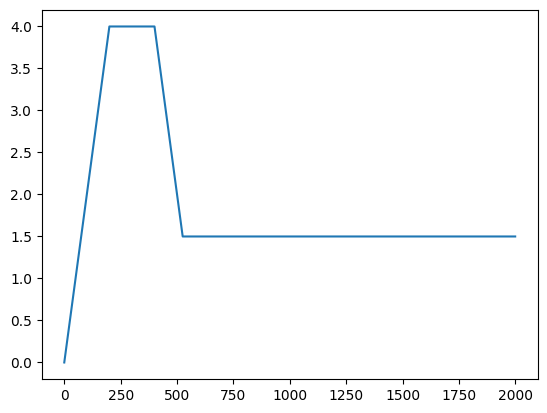

In [97]:
t_peaks = np.arange(50,201)
T_peaks = np.arange(1.0,4.0,step=0.1)
t_end=2000

plt.plot(TIPMIP_temps(T_peak=4.0,t_peak=200,t_end=t_end))

In [105]:
D = np.array([util.dynamics.evolve(np.zeros(9), A[r], t_end, 
                         T = TIPMIP_temps(T_peak=4,t_peak=200,t_end=t_end), 
                         tau_c=tau_c,pr=pr, beta=beta,T_lim=T_lim) for r in range(no_samples)])

In [106]:
D.shape

(500, 9, 2000)

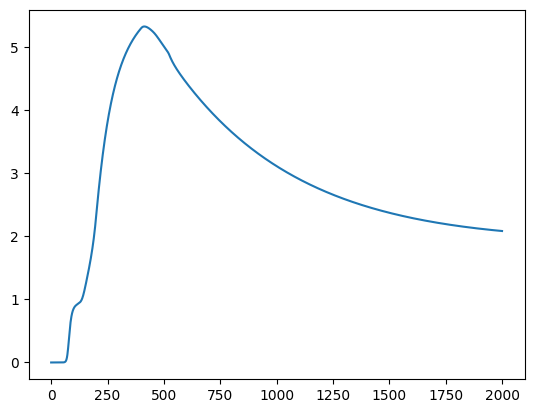

In [107]:
plt.plot(D.mean(axis=0).sum(axis=0))

In [115]:
t_peaks = np.arange(50,201,step=10)
T_peaks = np.arange(1.0,4.0,step=0.1)
t_end=2000
D = np.zeros((len(T_peaks), len(t_peaks),len(df_TEs), t_end))
for i,T in tqdm.tqdm(enumerate(T_peaks)):
    for j,t in enumerate(t_peaks):
        D[i,j,:,:] =  np.array([util.dynamics.evolve(np.zeros(9), A[r], t_end, 
                                                  T = TIPMIP_temps(T_peak=T,t_peak=t,t_end=t_end,T_conv=0), 
                                                  tau_c=tau_c,pr=pr, beta=beta,T_lim=T_lim) for r in range(no_samples)]).mean(axis=0)

30it [1:10:43, 141.47s/it]


In [126]:
D_Tpeak4 = np.zeros((len(t_peaks),len(df_TEs), t_end))
for j,t in tqdm.tqdm(enumerate(t_peaks)):
    D_Tpeak4[j,:,:] =  np.array([util.dynamics.evolve(np.zeros(9), A[r], t_end, 
                                                      T = TIPMIP_temps(T_peak=4.0,t_peak=t,t_end=t_end,T_conv=0), 
                                                      tau_c=tau_c,pr=pr, beta=beta,T_lim=T_lim) for r in range(no_samples)]).mean(axis=0)

16it [02:15,  8.44s/it]


In [154]:
D_fin.shape

(31, 16, 9, 2000)

In [127]:
D_fin = np.concatenate((D,D_Tpeak4.reshape(1,len(t_peaks),len(df_TEs), t_end)))

In [155]:
T_peaks = np.arange(1.0,4.1,step=0.1)
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        np.savetxt("../../Data/Simulations/TIPMIP/T%.1f_t%s.csv"%(T,t), D_fin[i,j,:,:])

## Plotting

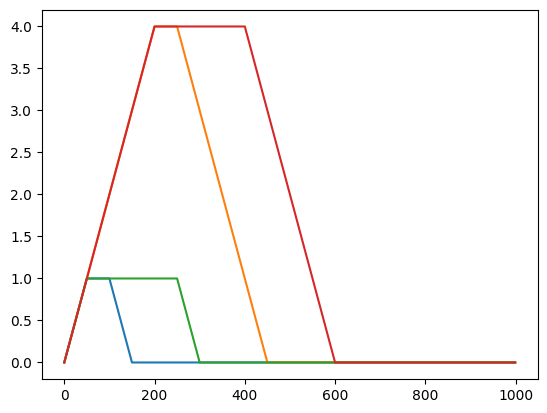

In [138]:
plt.plot(TIPMIP_temps(T_peak=1,t_peak=50,t_end=1000,T_conv=0))
plt.plot(TIPMIP_temps(T_peak=4,t_peak=50,t_end=1000,T_conv=0))
plt.plot(TIPMIP_temps(T_peak=1,t_peak=200,t_end=1000,T_conv=0))
plt.plot(TIPMIP_temps(T_peak=4,t_peak=200,t_end=1000,T_conv=0))

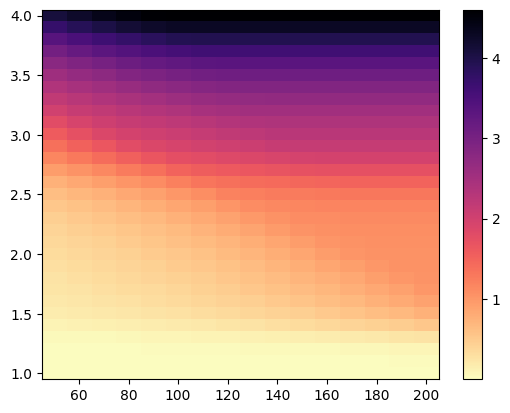

In [158]:
im = plt.imshow(D_fin.sum(axis=2)[:,:,300],extent=[50-5, 200+5, 1-0.05, 4+0.05],origin='lower',aspect='auto',cmap='magma_r')
plt.colorbar()

## plotting wrt position on the curve, not real time

### middle of the peak

In [156]:
D_peak = np.zeros((len(T_peaks),len(t_peaks)))
for i,T in enumerate(T_peaks):
    for j,t in enumerate(t_peaks):
        D_peak[i,j] = D_fin.sum(axis=2)[i,j,int(T/0.02 + t/2)]

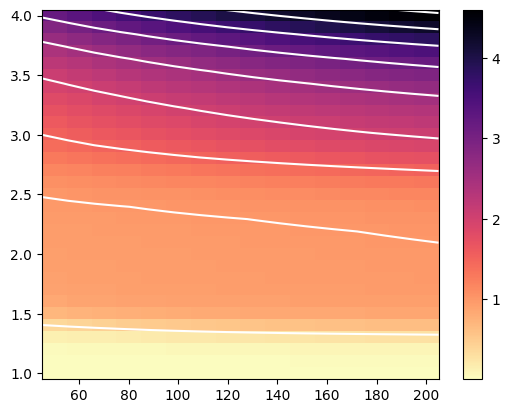

In [167]:
extent = [50-5, 200+5, 1-0.05, 4+0.05]
im = plt.imshow(D_peak,extent=extent,origin='lower',aspect='auto',cmap='magma_r')
plt.contour(D_peak,np.arange(0.5,5,step=0.5), extent=extent,colors='white')
plt.colorbar(im)

# Stylized temperatures from Wunderling 2023

In [75]:
def W23_temp(t, T_0 = 1, T_conv=2.0, gamma = 0.0963, mu_0 = 1.5e-3, mu_1= 1.83e-4):
    return T_0 + gamma*t - (1-np.exp(-mu_0*t - mu_1*t**2))*(gamma*t - T_conv + T_0)

def W23_peak_times(T_0 = 1, T_conv=2.0, gamma = 0.0963, mu_0 = 1.5e-3, mu_1= 1.83e-4):
    det = np.sqrt((mu_0*gamma + 2*mu_1*(T_conv-T_0))**2 + 8*mu_1*gamma**2)
    return ((mu_0*gamma - 2*mu_1*(T_conv-T_0) + det)/(-4*mu_1*gamma), 
            (mu_0*gamma - 2*mu_1*(T_conv-T_0) - det)/(-4*mu_1*gamma))

def W23_peak(T_0 = 1, T_conv=2.0, gamma = 0.0963, mu_0 = 1.5e-3, mu_1= 1.83e-4):
    return W23_temp(W23_peak_times(T_0 = T_0, T_conv=T_conv, gamma = gamma, mu_0 = mu_0, mu_1= mu_1)[-1],
                   T_0 = T_0, T_conv=T_conv, gamma = gamma, mu_0 = mu_0, mu_1= mu_1)

def W23_t_conv(**kwargs):
    return fsolve(lambda x: W23_res(x,**kwargs),W23_peak_times(**kwargs)[-1]+10)

def W23_res(t, **kwargs):
    return np.abs(W23_temp(t,**kwargs)-kwargs['T_conv'])-0.01

In [43]:
my_dict = dict(T_0 = 1, T_conv=2.0, gamma = 0.0963, mu_0 = 1.5e-3, mu_1= 1.83e-4)
T_peak = W23_peak(**my_dict)
print(T_peak)

4.275232052278555


In [46]:
my_dict['T_conv']

2.0

In [69]:
W23_peak_times(**my_dict)[-1]

np.float64(55.91296361401072)

In [76]:
print(W23_t_conv(**my_dict))

[198.40669597]


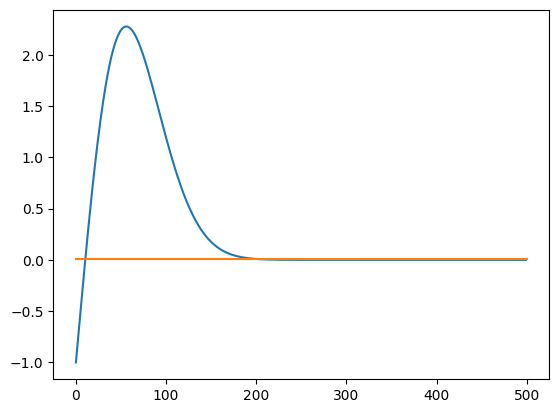

In [57]:
plt.plot(W23_temp(np.arange(500),**my_dict)-my_dict['T_conv'])
plt.plot([0,500],[0.01]*2)